In [71]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(0)

device = "mps" if torch.backends.mps.is_available() else "cpu"
print("Using device:", device)

Using device: mps


In [72]:
from torchvision import datasets, transforms
from torch.utils.data import random_split

transform = transforms.Compose([
   transforms.ToTensor(),
   transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_data = datasets.ImageFolder("data/train", transform=transform)
test_data = datasets.ImageFolder("data/test", transform = transform)

train_set, val_set = random_split(train_data, [0.9, 0.1])

train_loader = DataLoader(train_set, batch_size = 128, shuffle = True)
val_loader = DataLoader(val_set, batch_size = 128, shuffle = False)
test_loader = DataLoader(test_data, batch_size = 128, shuffle = False)


idx = train_data.class_to_idx
print(idx)
print(f"Train Set Lenght: {len(train_set)}")
print(f"Validation Set Lenght: {len(val_set)}")
print(f"Test Set Lenght: {len(test_data)}")

{'FAKE': 0, 'REAL': 1}
Train Set Lenght: 90000
Validation Set Lenght: 10000
Test Set Lenght: 20000


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9529412..0.5529412].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.79607844].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.78039217..0.9372549].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid rang

torch.Size([128, 3, 32, 32])
torch.Size([128])
torch.Size([3, 32, 32])
torch.Size([]) FAKE


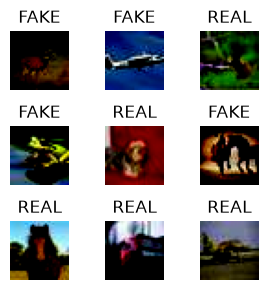

In [73]:
images, labels = next(iter(train_loader))
print(images.shape)
print(labels.shape)

img = images[0]
label = labels[0]
print(img.shape)
print(label.shape, train_data.classes[label])

fig, axes = plt.subplots(3, 3, figsize=(3, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].permute(1, 2, 0) * 0.5 + 0.5)
    ax.set_title(train_data.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.savefig("images/samples.png", dpi=150, bbox_inches="tight")
plt.show()


In [74]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(3072, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.layers(x)
        return x

In [75]:
model = MLP().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)

In [76]:
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0,0,0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
            
    return total_loss / total, correct / total

In [77]:
epochs = 20
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(epochs):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss, train_acc = evaluate(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch+1}: train loss {train_loss:.4f}, acc {train_acc:.4f} | val loss {val_loss:.4f}, acc {val_acc:.4f}")
        

Epoch 1: train loss 0.4469, acc 0.7862 | val loss 0.4601, acc 0.7772
Epoch 2: train loss 0.4158, acc 0.8092 | val loss 0.4371, acc 0.7937
Epoch 3: train loss 0.3871, acc 0.8230 | val loss 0.4205, acc 0.8022
Epoch 4: train loss 0.3781, acc 0.8259 | val loss 0.4213, acc 0.8019
Epoch 5: train loss 0.3507, acc 0.8456 | val loss 0.4006, acc 0.8164
Epoch 6: train loss 0.3323, acc 0.8568 | val loss 0.3908, acc 0.8186
Epoch 7: train loss 0.3167, acc 0.8632 | val loss 0.3872, acc 0.8184
Epoch 8: train loss 0.2975, acc 0.8739 | val loss 0.3806, acc 0.8266
Epoch 9: train loss 0.2848, acc 0.8801 | val loss 0.3828, acc 0.8290
Epoch 10: train loss 0.2712, acc 0.8870 | val loss 0.3720, acc 0.8310
Epoch 11: train loss 0.2582, acc 0.8938 | val loss 0.3693, acc 0.8332
Epoch 12: train loss 0.2542, acc 0.8971 | val loss 0.3723, acc 0.8298
Epoch 13: train loss 0.2307, acc 0.9052 | val loss 0.3707, acc 0.8353
Epoch 14: train loss 0.2228, acc 0.9139 | val loss 0.3602, acc 0.8382
Epoch 15: train loss 0.2089, 

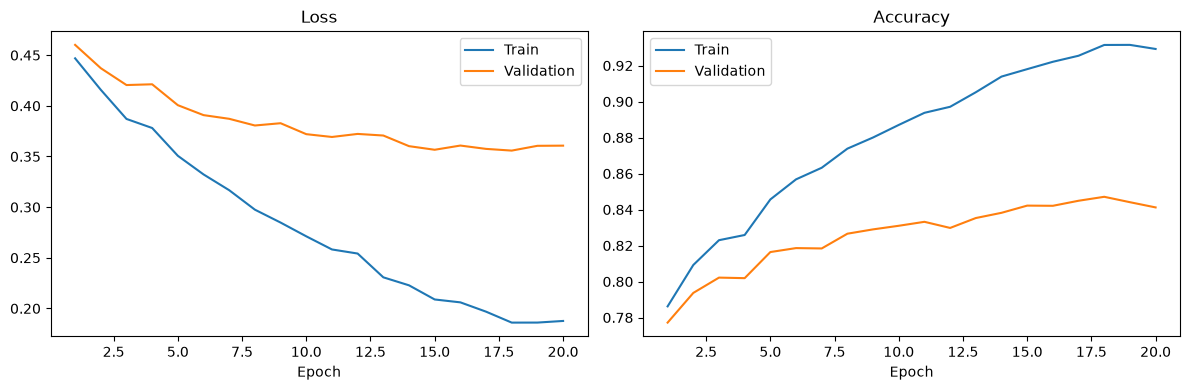

In [78]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_range, history["train_loss"], label="Train")
ax1.plot(epochs_range, history["val_loss"], label="Validation")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(epochs_range, history["train_acc"], label="Train")
ax2.plot(epochs_range, history["val_acc"], label="Validation")
ax2.set_title("Accuracy")
ax2.set_xlabel("Epoch")
ax2.legend()

plt.tight_layout()
plt.savefig("images/mlp.png", dpi=150, bbox_inches="tight")
plt.show()

In [81]:
import os
print(os.listdir("."))

test_loss, test_acc = evaluate(model, test_loader)
print(f"Test loss {test_loss:.4f}, acc {test_acc:.4f}")

['csc383_hw1.ipynb', 'csc383_hw3.ipynb', '.DS_Store', 'requirements.txt', 'csc383_hw2.ipynb', 'checkpoints', 'README.md', '.gitignore', '.ipynb_checkpoints', '.git', 'data', 'model.ipynb', 'src']
Test loss 0.3631, acc 0.8423
